<a href="https://colab.research.google.com/github/duartegonzaloariel/UDELAR_Astrometric-calibration-/blob/main/02_calibracion_red_single_multi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 · Calibración con redes neuronales: single-station, multi-station y ensemble

Usa la salida del notebook 01 (`df_global_con_ajuste.csv`): estrellas sin outliers y sin campañas excluidas.

**Esquema**
1. Split train/val/test **fijo por registro**, calculado una sola vez sobre todo el dataset. Single y multi usan exactamente los mismos puntos de test.
2. Ajuste clásico por campaña (centro libre, polinomio radial, rotación, paridad, inclinación) **solo con train**.
3. La red aprende el residuo en el plano tangente del cielo, en arcmin: Δz (cenit) y Δa·sin z (azimut), como la ec. 10 de Caldas et al.
4. Comparación sobre el mismo test: Caldas (`Xpred`) · clásico · red.

**Orden de corrida:** primero `ESTACION = 'global'` (multi) con un `MODEL_NAME`; después cada estación con el mismo `MODEL_NAME`. Cada corrida single agrega su fila a la Tabla 9 en Drive.

# 0. Inicialización

In [19]:
import os, copy, math
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F, torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from scipy.optimize import least_squares
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error
from IPython.display import display
from google.colab import drive
drive.mount('/content/drive')

pd.set_option('display.max_columns', None); pd.set_option('display.max_rows', 200); pd.set_option('display.width', None)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
display(pd.DataFrame({'device': [str(device)],
                      'gpu': [torch.cuda.get_device_name(0) if torch.cuda.is_available() else '-']}))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,device,gpu
0,cpu,-


## 0.1. Configuración

In [20]:
PATH_BASE     = "/content/drive/MyDrive/InvestigacionesPropias/Fireball/estrellas/calibracion/"
ARCHIVO_DATOS = "df_global_con_ajuste.csv"     # salida del notebook 01

MODEL_NAME = 'DENSE'      # 'DENSE' | 'DENSE_BAYESIAN' | 'CNN'
ESTACION   = '17'     # 'global' = multi-station | número (ej. 17) = single-station

LOOPS    = 5
EPOCHS   = 1000
PATIENCE = 50
BATCH    = 32
LR       = 1e-3
BETA_KL  = 0.01           # solo DENSE_BAYESIAN

SEED_SPLIT = 42           # NO cambiar entre corridas: define el split común de single y multi
FRAC_TEST  = 0.20
FRAC_VAL   = 0.20         # fracción del resto que va a validación
USAR_FECHA = False        # año/mes como features (el ajuste por campaña ya los absorbe)

STATION_ONEHOT_COLS = [f'station_{s}' for s in [1,2,3,4,5,6,7,8,9,10,12,13,14,15,16,17,19,20]]
ES_GLOBAL = str(ESTACION).strip().lower() == 'global'
TAG = f"{MODEL_NAME}_{'global' if ES_GLOBAL else 'st' + str(int(ESTACION))}"
torch.manual_seed(SEED_SPLIT); np.random.seed(SEED_SPLIT)
display(pd.DataFrame({'MODEL_NAME': [MODEL_NAME], 'ESTACION': [ESTACION], 'TAG': [TAG]}))

,MODEL_NAME,ESTACION,TAG
0,DENSE,17,DENSE_st17


# 1. Datos
## 1.1. Carga

In [21]:
df = pd.read_csv(os.path.join(PATH_BASE, ARCHIVO_DATOS))
df = df[(~df['excluida']) & (~df['outlier'])].reset_index(drop=True)
df['rid'] = np.arange(len(df))          # id de registro, estable entre corridas
display(df.head())
display(pd.DataFrame({'registros': [len(df)], 'campañas': [df['campaña'].nunique()],
                      'estaciones': [df['station'].nunique()]}))

,station,año,mes,Posicion_Y,Posicion_X,azimuth,altitude,Posicion_Ypred,Posicion_Xpred,zenith,campaña,excluida,err_mio,err_caldas,err_caldas_px,outlier,banda_z,rid
0,1,2022,9,541,869,158.494,76.494,556,885,13.506,1_2022-09,False,5.642034,140.603492,21.931712,False,"(0, 30]",0
1,1,2022,9,486,867,184.884,77.475,504,881,12.525,1_2022-09,False,8.354842,145.777872,22.803509,False,"(0, 30]",1
2,1,2022,9,586,710,65.015,79.503,604,741,10.497,1_2022-09,False,6.593029,230.432861,35.846897,False,"(0, 30]",2
3,1,2022,9,734,1038,139.870,49.255,729,1056,40.745,1_2022-09,False,3.692889,119.014418,18.681542,False,"(30, 50]",3
4,1,2022,9,279,1191,205.629,35.018,289,1187,54.982,1_2022-09,False,8.058011,73.070666,10.770330,False,"(50, 60]",4


,registros,campañas,estaciones
0,8558,32,18


## 1.2. Split fijo train / val / test
Estratificado por campaña. Se guarda en Drive la primera vez y se reusa en todas las corridas siguientes.

In [22]:
SPLIT_FILE = os.path.join(PATH_BASE, f"split_seed{SEED_SPLIT}.csv")

if os.path.exists(SPLIT_FILE):
    sp = pd.read_csv(SPLIT_FILE)
    assert len(sp) == len(df), "El split guardado no coincide con los datos: borrá el archivo de split y volvé a correr."
    df['split'] = sp['split'].values
    origen_split = 'leído de Drive'
else:
    rng = np.random.default_rng(SEED_SPLIT)
    df['split'] = 'train'
    for camp, g in df.groupby('campaña'):
        idx = rng.permutation(g.index.values)
        n_test = int(round(FRAC_TEST * len(idx)))
        n_val  = int(round(FRAC_VAL * (len(idx) - n_test)))
        df.loc[idx[:n_test], 'split'] = 'test'
        df.loc[idx[n_test:n_test + n_val], 'split'] = 'val'
    df[['rid', 'campaña', 'split']].to_csv(SPLIT_FILE, index=False)
    origen_split = 'creado y guardado'

display(pd.DataFrame({'split': [origen_split]}))
display(df['split'].value_counts().to_frame('N').T)

,split
0,leído de Drive


split,train,test,val
N,5474,1714,1370


## 1.3. Modelo geométrico (igual que el notebook 01)

In [23]:
K = 60 * 180 / np.pi        # rad -> arcmin

def vec(z_deg, a_deg):
    z, a = np.deg2rad(z_deg), np.deg2rad(a_deg)
    return np.stack([np.sin(z)*np.cos(a), np.sin(z)*np.sin(a), np.cos(z)], axis=-1)

def to_za(v):
    v = v / np.linalg.norm(v, axis=-1, keepdims=True)
    return np.rad2deg(np.arccos(np.clip(v[..., 2], -1, 1))), np.rad2deg(np.arctan2(v[..., 1], v[..., 0])) % 360

def sep_arcmin(v1, v2):
    return np.rad2deg(np.arccos(np.clip(np.sum(v1*v2, axis=-1), -1, 1))) * 60

def modelo(p, x, y, paridad, devolver_camara=False):
    x0, y0, a0, p1, p2, p3, eps, E = p
    dx, dy = x - x0, y - y0
    r = np.hypot(dx, dy)
    phi = np.rad2deg(np.arctan2(dy, dx))
    zc = p1*r + p2*r**2 + p3*r**3
    v = vec(zc, a0 + paridad*phi)
    e, t = np.deg2rad(E), np.deg2rad(eps)
    Rz = lambda g: np.array([[np.cos(g), -np.sin(g), 0], [np.sin(g), np.cos(g), 0], [0, 0, 1]])
    Ry = np.array([[np.cos(t), 0, np.sin(t)], [0, 1, 0], [-np.sin(t), 0, np.cos(t)]])
    v = v @ (Rz(e) @ Ry @ Rz(-e)).T
    if devolver_camara:
        return v, zc, paridad*phi, r
    return v

def ajustar(x, y, z, a):
    v_obs = vec(z, a)
    cx, cy = np.median(x), np.median(y)
    r0 = np.hypot(x - cx, y - cy)
    p1_0 = np.sum(r0*z) / np.sum(r0**2)
    mejor = None
    for par in (+1, -1):
        phi0 = np.rad2deg(np.arctan2(y - cy, x - cx))
        d = np.deg2rad(a - par*phi0)
        a0_0 = np.rad2deg(np.arctan2(np.sin(d).mean(), np.cos(d).mean()))
        f = lambda p: (modelo(p, x, y, par) - v_obs).ravel()
        res = least_squares(f, [cx, cy, a0_0, p1_0, 0.0, 0.0, 0.5, 0.0],
                            x_scale=[50, 50, 10, p1_0, p1_0/500, p1_0/2.5e5, 1, 30],
                            loss='soft_l1', f_scale=np.deg2rad(0.5), max_nfev=4000)
        err = sep_arcmin(modelo(res.x, x, y, par), v_obs)
        if mejor is None or np.median(err) < np.median(mejor['err']):
            mejor = dict(p=res.x, paridad=par, err=err)
    return mejor

def base_tangente(z_deg, a_deg):
    """Vectores unitarios en la dirección de z creciente (e_z) y de azimut creciente (e_a)."""
    z, a = np.deg2rad(z_deg), np.deg2rad(a_deg)
    e_z = np.stack([np.cos(z)*np.cos(a), np.cos(z)*np.sin(a), -np.sin(z)], axis=-1)
    e_a = np.stack([-np.sin(a), np.cos(a), np.zeros_like(a)], axis=-1)
    return e_z, e_a

def reconstruir(v_cl, e_z, e_a, t):
    """Clásico + residuo (t = [Δz, Δa·sin z] en arcmin) -> vector unitario predicho."""
    v = v_cl + (t[:, [0]] * e_z + t[:, [1]] * e_a) / K
    return v / np.linalg.norm(v, axis=-1, keepdims=True)

## 1.4. Ajuste clásico por campaña (solo train) y residuos

In [24]:
df['zenith'] = 90.0 - df['altitude']
v_true = vec(df['zenith'].values, df['azimuth'].values)
v_cl = np.zeros_like(v_true)
for c in ['z_cam', 'phi_cam', 'r_px']:
    df[c] = np.nan

PARAMS_CLASICO, filas = {}, []
for camp, g in df.groupby('campaña'):
    tr = g[g['split'] == 'train']
    fit = ajustar(tr['Posicion_X'].values.astype(float), tr['Posicion_Y'].values.astype(float),
                  tr['zenith'].values, tr['azimuth'].values)
    PARAMS_CLASICO[camp] = dict(p=fit['p'].tolist(), paridad=int(fit['paridad']))
    v, zc, phic, r = modelo(fit['p'], g['Posicion_X'].values.astype(float), g['Posicion_Y'].values.astype(float),
                            fit['paridad'], devolver_camara=True)
    v_cl[g.index.values] = v
    df.loc[g.index, 'z_cam'], df.loc[g.index, 'phi_cam'], df.loc[g.index, 'r_px'] = zc, phic, r
    e = sep_arcmin(v, v_true[g.index.values])
    m_te = (g['split'] == 'test').values
    filas.append(dict(campaña=camp, N=len(g), N_train=len(tr), paridad=fit['paridad'],
                      escala=fit['p'][3]*60, x0=fit['p'][0], y0=fit['p'][1], incl=abs(fit['p'][6]),
                      clasico_train_med=np.median(e[~m_te]), clasico_test_med=np.median(e[m_te]),
                      caldas_test_med=g.loc[m_te, 'err_caldas'].median()))

df['z_cl'], df['a_cl'] = to_za(v_cl)
e_z, e_a = base_tangente(df['z_cl'].values, df['a_cl'].values)
df['t_z'] = np.sum(v_true * e_z, axis=1) * K       # residuo en cenit (arcmin)
df['t_a'] = np.sum(v_true * e_a, axis=1) * K       # residuo en azimut · sin z (arcmin)
df['err_clasico'] = sep_arcmin(v_cl, v_true)

display(pd.DataFrame(filas).set_index('campaña').round(2))

,N,N_train,paridad,escala,x0,y0,incl,clasico_train_med,clasico_test_med,caldas_test_med
campaña,,,,,,,,,,
10_2023-02,197,126,-1,6.51,787.02,533.60,1.66,5.74,4.14,12.80
10_2023-05,222,142,-1,6.50,787.20,534.33,4.60,5.13,4.99,9.07
12_2023-05,354,226,-1,6.42,800.67,479.83,1.50,12.66,12.68,13.97
13_2023-03,354,226,-1,6.41,794.89,443.30,1.69,5.92,6.35,9.03
14_2023-02,341,218,-1,6.50,783.85,498.43,2.19,5.69,6.66,14.34
15_2023-02,396,254,-1,6.47,768.62,492.56,2.34,5.13,4.57,9.20
16_2023-05,180,115,-1,6.46,791.80,502.69,3.22,5.18,5.00,13.65
17_2023-03,350,224,-1,6.50,804.51,488.41,1.46,6.34,6.08,9.12
19_2023-05,154,98,-1,6.47,820.74,476.77,2.18,6.13,7.34,17.83


## 1.5. Selección single / multi, features y targets

In [25]:
for col in STATION_ONEHOT_COLS:
    df[col] = (df['station'] == int(col.split('_')[1])).astype(int)

df['sin_phi_cam'], df['cos_phi_cam'] = np.sin(np.deg2rad(df['phi_cam'])), np.cos(np.deg2rad(df['phi_cam']))
df['sin_a_cl'],   df['cos_a_cl']    = np.sin(np.deg2rad(df['a_cl'])),    np.cos(np.deg2rad(df['a_cl']))
df['mes_sin'], df['mes_cos'] = np.sin(2*np.pi*df['mes']/12), np.cos(2*np.pi*df['mes']/12)

# Features continuas: geometría en el marco de la cámara (distorsión de la lente) y en el horizonte (refracción)
CONT_FEATURES = ['z_cam', 'sin_phi_cam', 'cos_phi_cam', 'z_cl', 'sin_a_cl', 'cos_a_cl']
if USAR_FECHA:
    CONT_FEATURES += ['año', 'mes_sin', 'mes_cos']
COLUMNS_DATA   = CONT_FEATURES + STATION_ONEHOT_COLS
COLUMNS_TARGET = ['t_z', 't_a']
OUTPUT_SIZE    = len(COLUMNS_TARGET)

dfm = df if ES_GLOBAL else df[df['station'] == int(ESTACION)]
assert len(dfm) > 0, f"No hay datos para la estación {ESTACION}"

tr, va, te = [dfm[dfm['split'] == s] for s in ('train', 'val', 'test')]
x_scaler = StandardScaler().fit(tr[CONT_FEATURES].values)
y_scaler = StandardScaler().fit(tr[COLUMNS_TARGET].values)

def armar_X(d):
    return np.hstack([x_scaler.transform(d[CONT_FEATURES].values), d[STATION_ONEHOT_COLS].values]).astype('float32')

class SkyDataset(Dataset):
    def __init__(self, d):
        self.features = armar_X(d)
        self.targets  = y_scaler.transform(d[COLUMNS_TARGET].values).astype('float32')
    def __len__(self): return len(self.features)
    def __getitem__(self, i):
        return {'features': torch.tensor(self.features[i]), 'targets': torch.tensor(self.targets[i]), 'idx': i}

train_loader = DataLoader(SkyDataset(tr), batch_size=BATCH, shuffle=True, drop_last=True)
val_loader   = DataLoader(SkyDataset(va), batch_size=BATCH, shuffle=False)
criterion = nn.MSELoss()

display(pd.DataFrame({'modo': ['multi' if ES_GLOBAL else 'single'], 'train': [len(tr)], 'val': [len(va)],
                      'test': [len(te)], 'n_features': [len(COLUMNS_DATA)], 'targets': [COLUMNS_TARGET]}))
display(dfm[COLUMNS_DATA + COLUMNS_TARGET].describe().T.round(3))

,modo,train,val,test,n_features,targets
0,single,224,56,70,24,"[t_z, t_a]"


,count,mean,std,min,25%,50%,75%,max
z_cam,350.0,41.895,16.339,3.354,29.854,43.006,54.500,75.562
sin_phi_cam,350.0,0.011,0.662,-1.000,-0.645,0.071,0.622,1.000
cos_phi_cam,350.0,-0.205,0.723,-1.000,-0.833,-0.468,0.601,1.000
z_cl,350.0,42.034,16.363,4.139,29.390,42.572,54.641,76.284
sin_a_cl,350.0,0.109,0.680,-1.000,-0.577,0.202,0.771,1.000
cos_a_cl,350.0,-0.184,0.703,-1.000,-0.807,-0.463,0.541,1.000
station_1,350.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
station_2,350.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
station_3,350.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
station_4,350.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000


# 2. Modelos (sin cambios respecto al notebook anterior)

In [26]:
class SkyCoordinatesModel(nn.Module):
    def __init__(self, input_size, output_size):
        super(SkyCoordinatesModel, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.BatchNorm1d(128),
            nn.Linear(128, 256),

            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, output_size)
        )

    def forward(self, x):

        return self.network(x)

    def predict_with_uncertainty(self, x, n_samples=30):
        """
        NUEVO: incertidumbre vía MC-Dropout. A diferencia del modelo
        Bayesiano (que usa LayerNorm, indiferente a train/eval), este
        modelo tiene BatchNorm1d: llamar self.train() a secas activaría
        también el BatchNorm en modo batch-stats, corrompiendo sus
        estadisticas acumuladas (running_mean/running_var) como efecto
        secundario, incluso dentro de no_grad(). Por eso el modelo se deja
        en eval() (BatchNorm usa sus stats acumuladas, sin tocarlas) y se
        fuerza SOLO el Dropout a modo train, a mano.
        Devuelve (media, desvio_estandar) por muestra, igual formato que
        BayesianSkyCoordinatesModel.predict_with_uncertainty().
        """
        self.eval()
        for module in self.modules():
            if isinstance(module, nn.Dropout):
                module.train()

        preds = []
        with torch.no_grad():
            for _ in range(n_samples):
                preds.append(self.forward(x))
        preds = torch.stack(preds, dim=0)  # (n_samples, batch, output_size)
        mean = preds.mean(dim=0)
        std  = preds.std(dim=0)

        self.eval()  # restaurar todo (dropout incluido) a eval limpio
        return mean, std


In [27]:
# --- Corrección completa (robusta y lista para usar) ---
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

class BayesianLinear(nn.Module):
    def __init__(self, in_features, out_features, init_logvar=-8.0, prior_var=1.0):
        super().__init__()
        # Medias
        self.weight_mu = nn.Parameter(torch.zeros(out_features, in_features))
        self.bias_mu   = nn.Parameter(torch.zeros(out_features))
        # Varianzas log (menos extremas que -10 para permitir aprender incertidumbre)
        self.weight_logvar = nn.Parameter(torch.ones(out_features, in_features) * init_logvar)
        self.bias_logvar   = nn.Parameter(torch.ones(out_features) * init_logvar)

        # NUEVO: prior de los pesos, Normal(0, prior_var). Se usa en kl_divergence().
        self.prior_var = prior_var

    def forward(self, x):
        if self.training:
            # Reparametrización: mu + sigma * eps (solo durante el entrenamiento,
            # necesario para propagar gradientes a través del sampling)
            weight_std = torch.exp(0.5 * self.weight_logvar)
            bias_std   = torch.exp(0.5 * self.bias_logvar)

            weight = self.weight_mu + weight_std * torch.randn_like(weight_std)
            bias   = self.bias_mu   + bias_std   * torch.randn_like(bias_std)
        else:
            # En evaluación usamos la media de la posterior (predicción determinista,
            # comparable con Dense/CNN en vez de variar en cada llamada)
            weight = self.weight_mu
            bias   = self.bias_mu

        return F.linear(x, weight, bias)

    def kl_divergence(self):
        """
        NUEVO: KL(q(w) || p(w)) entre la posterior aprendida (weight_mu,
        weight_logvar) y un prior Normal(0, prior_var), sumada sobre todos
        los pesos y bias de esta capa. Sin este término, weight_logvar no
        tiene ninguna presión hacia un prior razonable y la capa "bayesiana"
        termina siendo solo ruido de entrenamiento sin sentido probabilístico.
        """
        log_prior_var = math.log(self.prior_var)

        kl_w = 0.5 * torch.sum(
            (self.weight_mu ** 2 + torch.exp(self.weight_logvar)) / self.prior_var
            - self.weight_logvar + log_prior_var - 1.0
        )
        kl_b = 0.5 * torch.sum(
            (self.bias_mu ** 2 + torch.exp(self.bias_logvar)) / self.prior_var
            - self.bias_logvar + log_prior_var - 1.0
        )
        return kl_w + kl_b


class BayesianSkyCoordinatesModel(nn.Module):
    """
    Tronco compartido + 'heads' por salida (mejor para sesgos distintos en X e Y).
    Si output_size == 1 -> una sola head. Si >1 -> N heads y se concatenan.
    """
    def __init__(self, input_size, output_size):
        super().__init__()
        self.trunk = nn.Sequential(
            BayesianLinear(input_size, 128),
            nn.ReLU(),
            nn.LayerNorm(128),           # más estable que BatchNorm con batches chicos
            BayesianLinear(128, 256),
            nn.ReLU(),
            nn.Dropout(0.30),
            BayesianLinear(256, 128),
            nn.ReLU(),
        )
        if output_size == 1:
            self.heads = nn.ModuleList([BayesianLinear(128, 1)])
        else:
            self.heads = nn.ModuleList([BayesianLinear(128, 1) for _ in range(output_size)])

    def forward(self, x):
        h = self.trunk(x)
        outs = [head(h) for head in self.heads]
        return torch.cat(outs, dim=1)

    def kl_divergence(self):
        """NUEVO: suma la KL de todas las capas BayesianLinear del modelo (trunk + heads)."""
        kl = 0.0
        for module in self.modules():
            if isinstance(module, BayesianLinear):
                kl = kl + module.kl_divergence()
        return kl

    def predict_with_uncertainty(self, x, n_samples=30):
        """
        NUEVO: hace n_samples pasadas hacia adelante muestreando pesos
        distintos cada vez (activa el modo 'training' de las capas
        BayesianLinear aunque no se actualicen gradientes), y devuelve
        (media, desvio_estandar) por muestra. El desvio es tu estimador de
        incertidumbre por predicción, util por ejemplo para pesar cada
        observacion en la triangulación de trayectorias.
        NOTA: al llamar self.train(), el Dropout(0.30) del trunk tambien se
        activa durante el muestreo (LayerNorm no se ve afectado, no tiene
        estadisticas acumuladas como BatchNorm). Esto suma una fuente extra
        de variabilidad ademas de la incertidumbre de los pesos, lo cual es
        razonable pero vale tenerlo en cuenta al interpretar el desvio.
        """
        was_training = self.training
        self.train()
        preds = []
        with torch.no_grad():
            for _ in range(n_samples):
                preds.append(self.forward(x))
        preds = torch.stack(preds, dim=0)  # (n_samples, batch, output_size)
        mean = preds.mean(dim=0)
        std  = preds.std(dim=0)
        if not was_training:
            self.eval()
        return mean, std


In [28]:
class CNNModel(nn.Module):
    def __init__(self, input_size, output_size):
        super(CNNModel, self).__init__()
        self.conv1 = nn.Conv1d(in_channels=input_size, out_channels=128, kernel_size=1)
        self.bn1   = nn.BatchNorm1d(128)
        self.conv2 = nn.Conv1d(in_channels=128, out_channels=256, kernel_size=1)
        self.bn2   = nn.BatchNorm1d(256)
        self.drop  = nn.Dropout(0.3)
        self.fc1   = nn.Linear(256, 128)
        self.fc2   = nn.Linear(128, output_size)

    def forward(self, x):
        x = x.unsqueeze(2)
        x = torch.relu(self.bn1(self.conv1(x)))
        x = torch.relu(self.bn2(self.conv2(x)))
        x = x.mean(dim=-1)
        x = self.drop(x)
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x

    def predict_with_uncertainty(self, x, n_samples=30):
        """
        NUEVO: incertidumbre vía MC-Dropout. Igual criterio que en
        SkyCoordinatesModel (DENSE): este modelo tiene BatchNorm1d (bn1,
        bn2), así que NO se puede llamar self.train() a secas (corrompería
        las estadisticas acumuladas de BatchNorm como efecto secundario,
        incluso dentro de no_grad()). Se deja el modelo en eval() y se
        fuerza SOLO self.drop a modo train, a mano.
        Devuelve (media, desvio_estandar) por muestra, mismo formato que
        los otros dos modelos.
        """
        self.eval()
        self.drop.train()  # unico modulo de Dropout en este modelo

        preds = []
        with torch.no_grad():
            for _ in range(n_samples):
                preds.append(self.forward(x))
        preds = torch.stack(preds, dim=0)  # (n_samples, batch, output_size)
        mean = preds.mean(dim=0)
        std  = preds.std(dim=0)

        self.eval()  # restaurar todo (dropout incluido) a eval limpio
        return mean, std


In [29]:
def get_Model(model_name, device):
    clases = {'DENSE': SkyCoordinatesModel, 'DENSE_BAYESIAN': BayesianSkyCoordinatesModel, 'CNN': CNNModel}
    model = clases[model_name](input_size=len(COLUMNS_DATA), output_size=OUTPUT_SIZE).to(device)
    return model, optim.Adam(model.parameters(), lr=LR)

## 2.1. Función de entrenamiento (sin cambios)

In [30]:
# Ciclo de entrenamiento
import copy

def train_model(model, dataloader, val_dataloader, criterion, optimizer, epochs=100,
                patience=50, debug=True, beta_kl=1.0):
    """
    NUEVO: beta_kl pondera el termino de divergencia KL, que solo se suma
    cuando el modelo la tiene (model.kl_divergence(), como
    BayesianSkyCoordinatesModel) -- DENSE y CNN no tienen ese metodo, asi
    que para ellos el entrenamiento queda identico a como era antes.
    La KL total se reparte entre los minibatches de cada epoca (kl /
    n_batches), siguiendo el esquema estandar de Bayes-by-Backprop
    (Blundell et al. 2015) para que el ELBO quede bien escalado.
    """
    has_kl = hasattr(model, 'kl_divergence')
    n_batches = len(dataloader)

    loss_list, mse_list = [], []
    val_loss_list = []

    best_val_loss = float("inf")
    best_state = None
    patience_counter = 0

    for epoch in range(epochs):
        # ============================
        # TRAIN
        # ============================
        model.train()
        running_loss = 0.0
        all_outputs, all_targets = [], []

        for batch in dataloader:
            inputs = batch['features'].to(device)
            targets = batch['targets'].to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            data_loss = criterion(outputs, targets)

            # NUEVO: termino KL, solo si el modelo lo soporta (Bayesiano)
            if has_kl:
                kl = model.kl_divergence()
                loss = data_loss + beta_kl * kl / n_batches
            else:
                loss = data_loss

            loss.backward()
            optimizer.step()

            # se registra solo la data_loss (comparable entre arquitecturas,
            # sin el termino de regularizacion KL)
            running_loss += data_loss.item()
            all_outputs.append(outputs.detach().cpu())
            all_targets.append(targets.detach().cpu())

        # Métricas de la época (TRAIN)
        all_outputs = torch.cat(all_outputs)
        all_targets = torch.cat(all_targets)

        mse = mean_squared_error(all_targets, all_outputs)
        mse_list.append(mse)

        epoch_loss = running_loss / len(dataloader)
        loss_list.append(epoch_loss)

        # ============================
        # VALIDATION
        # (sin termino KL: medimos precision predictiva pura, igual que en
        # DENSE/CNN, para que el early stopping y la comparacion entre
        # arquitecturas sigan siendo comparables)
        # ============================
        model.eval()
        val_running_loss = 0.0
        with torch.no_grad():
            for batch in val_dataloader:
                inputs = batch['features'].to(device)
                targets = batch['targets'].to(device)

                outputs = model(inputs)
                loss = criterion(outputs, targets)
                val_running_loss += loss.item()

        epoch_val_loss = val_running_loss / len(val_dataloader)
        val_loss_list.append(epoch_val_loss)

        # Print
        if debug and (epoch % 100 == 0 or epoch == epochs - 1):
            print(f"Epoch {epoch+1}/{epochs}, Train Loss: {epoch_loss:.4f}, "
                  f"Val Loss: {epoch_val_loss:.4f}, MSE: {mse:.4f}")

        # ============================
        # EARLY STOPPING (según VALIDATION, no TRAIN)
        # ============================
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"\n⛔ Early stopping activado en epoch {epoch+1} (mejor val_loss: {best_val_loss:.4f})")
                break

    # Restaurar mejor modelo (según validación, no según train)
    if best_state is not None:
        model.load_state_dict(best_state)

    return loss_list, mse_list, val_loss_list


# 3. Entrenamiento (LOOPS corridas, se elige por validación)

In [31]:
def predecir(model, d):
    model.eval()
    with torch.no_grad():
        out = model(torch.tensor(armar_X(d)).to(device)).cpu().numpy()
    return y_scaler.inverse_transform(out)     # residuo en arcmin

def error_red(d, t_pred):
    idx = d.index.values
    return sep_arcmin(reconstruir(v_cl[idx], e_z[idx], e_a[idx], t_pred), v_true[idx])

runs = []
for loop in range(LOOPS):
    torch.manual_seed(SEED_SPLIT + loop)
    model, optimizer = get_Model(MODEL_NAME, device)
    loss, mse, val_loss = train_model(model, train_loader, val_loader, criterion, optimizer,
                                      epochs=EPOCHS, patience=PATIENCE, debug=False, beta_kl=BETA_KL)
    runs.append(dict(loop=loop + 1, val_loss=min(val_loss), state=copy.deepcopy(model.state_dict()),
                     loss=loss, mse=mse, val_curve=val_loss, epocas=len(loss),
                     test_med=np.median(error_red(te, predecir(model, te)))))

best = min(runs, key=lambda r: r['val_loss'])
model, _ = get_Model(MODEL_NAME, device)
model.load_state_dict(best['state'])

resumen_loops = pd.DataFrame([{k: r[k] for k in ['loop', 'val_loss', 'epocas', 'test_med']} for r in runs])
resumen_loops['elegido'] = resumen_loops['loop'] == best['loop']
resumen_loops = resumen_loops.rename(columns={'test_med': 'test_mediana_arcmin (solo referencia)'})
display(resumen_loops.round(4))


⛔ Early stopping activado en epoch 63 (mejor val_loss: 0.5710)

⛔ Early stopping activado en epoch 71 (mejor val_loss: 0.6115)

⛔ Early stopping activado en epoch 69 (mejor val_loss: 0.6207)

⛔ Early stopping activado en epoch 66 (mejor val_loss: 0.6032)

⛔ Early stopping activado en epoch 88 (mejor val_loss: 0.6265)


,loop,val_loss,epocas,test_mediana_arcmin (solo referencia),elegido
0,1,0.5710,63,4.4923,True
1,2,0.6115,71,4.2490,False
2,3,0.6207,69,4.6527,False
3,4,0.6032,66,4.6406,False
4,5,0.6265,88,4.5444,False


# 4. Evaluación
## 4.1. Tabla de desempeño (formato Tablas 2–4 y 6–8 del paper)

In [32]:
def metricas(d, v_pred):
    idx = d.index.values
    z_t, a_t = d['zenith'].values, d['azimuth'].values
    z_p, a_p = to_za(v_pred)
    daz = (a_p - a_t + 180) % 360 - 180
    sep = sep_arcmin(v_pred, v_true[idx])
    return {
        'Azimuth RMSE (deg)': np.sqrt(np.mean(daz**2)),
        'Azimuth RMSE (arcmin)': 60*np.sqrt(np.mean(daz**2)),
        'Zenith RMSE (deg)': np.sqrt(np.mean((z_p - z_t)**2)),
        'Zenith RMSE (arcmin)': 60*np.sqrt(np.mean((z_p - z_t)**2)),
        'R2 azimuth sin': r2_score(np.sin(np.deg2rad(a_t)), np.sin(np.deg2rad(a_p))),
        'R2 azimuth cos': r2_score(np.cos(np.deg2rad(a_t)), np.cos(np.deg2rad(a_p))),
        'R2 zenith': r2_score(z_t, z_p),
        'Sky angular separation RMSE (arcmin)': np.sqrt(np.mean(sep**2)),
        'Sky angular separation MAE (arcmin)': np.mean(sep),
        'Sky angular separation median (arcmin)': np.median(sep),
    }

def v_red(d):
    idx = d.index.values
    return reconstruir(v_cl[idx], e_z[idx], e_a[idx], predecir(model, d))

tabla_modelo = pd.DataFrame({'Train': metricas(tr, v_red(tr)), 'Test': metricas(te, v_red(te))})
print(f"Performance of the {MODEL_NAME} model ({'multi-station' if ES_GLOBAL else 'single station, station ' + str(ESTACION)}, best of LOOP = {LOOPS}, LOOP {best['loop']} selected)")
display(tabla_modelo.round(4))

Performance of the DENSE model (single station, station 17, best of LOOP = 5, LOOP 1 selected)


,Train,Test
Azimuth RMSE (deg),0.2590,0.2853
Azimuth RMSE (arcmin),15.5400,17.1205
Zenith RMSE (deg),0.0708,0.0960
Zenith RMSE (arcmin),4.2499,5.7613
R2 azimuth sin,1.0000,1.0000
R2 azimuth cos,1.0000,1.0000
R2 zenith,1.0000,1.0000
Sky angular separation RMSE (arcmin),5.8005,10.0677
Sky angular separation MAE (arcmin),4.8087,6.2810
Sky angular separation median (arcmin),4.2330,4.4923


## 4.2. Comparación sobre el mismo test: Caldas · clásico · red (arcmin)

In [33]:
def resumen(e):
    return {'N': len(e), 'mediana': np.median(e), 'MAE': np.mean(e), 'RMSE': np.sqrt(np.mean(e**2)), 'P90': np.percentile(e, 90)}

err_test_red = sep_arcmin(v_red(te), v_true[te.index.values])
comparacion = pd.DataFrame({'Caldas (Xpred)': resumen(te['err_caldas'].values),
                            'Clásico propio': resumen(te['err_clasico'].values),
                            f'Clásico + {MODEL_NAME}': resumen(err_test_red)}).T
display(comparacion.round(2))

bandas = pd.cut(te['zenith'], [0, 30, 50, 60, 70, 80, 90])
por_z = pd.DataFrame({'banda_z': bandas, 'caldas': te['err_caldas'].values,
                      'clasico': te['err_clasico'].values, 'red': err_test_red}).groupby('banda_z', observed=True)
display(pd.concat([por_z.size().rename('N'), por_z.median().add_suffix('_med')], axis=1).round(2))

,N,mediana,MAE,RMSE,P90
Caldas (Xpred),70.0,9.12,17.05,30.95,34.95
Clásico propio,70.0,6.08,7.03,10.44,10.21
Clásico + DENSE,70.0,4.49,6.28,10.07,9.47


,N,caldas_med,clasico_med,red_med
banda_z,,,,
"(0, 30]",23,9.28,5.67,4.89
"(30, 50]",26,6.47,6.29,3.63
"(50, 60]",14,7.13,6.04,4.50
"(60, 70]",6,10.62,5.44,9.03
"(70, 80]",1,81.04,28.72,8.67


## 4.3. Figuras (formato Figs. 1–4 del paper)

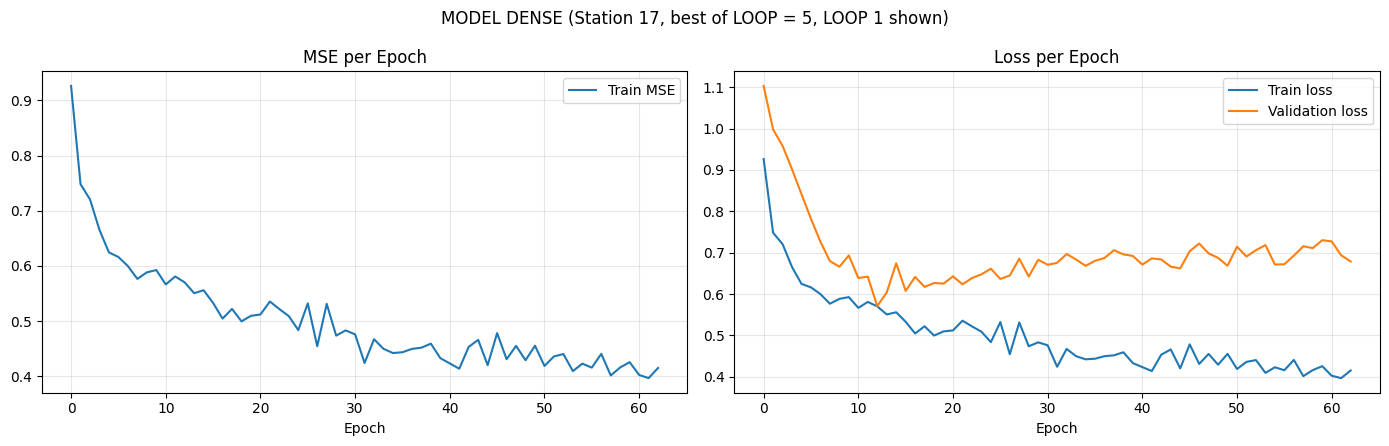

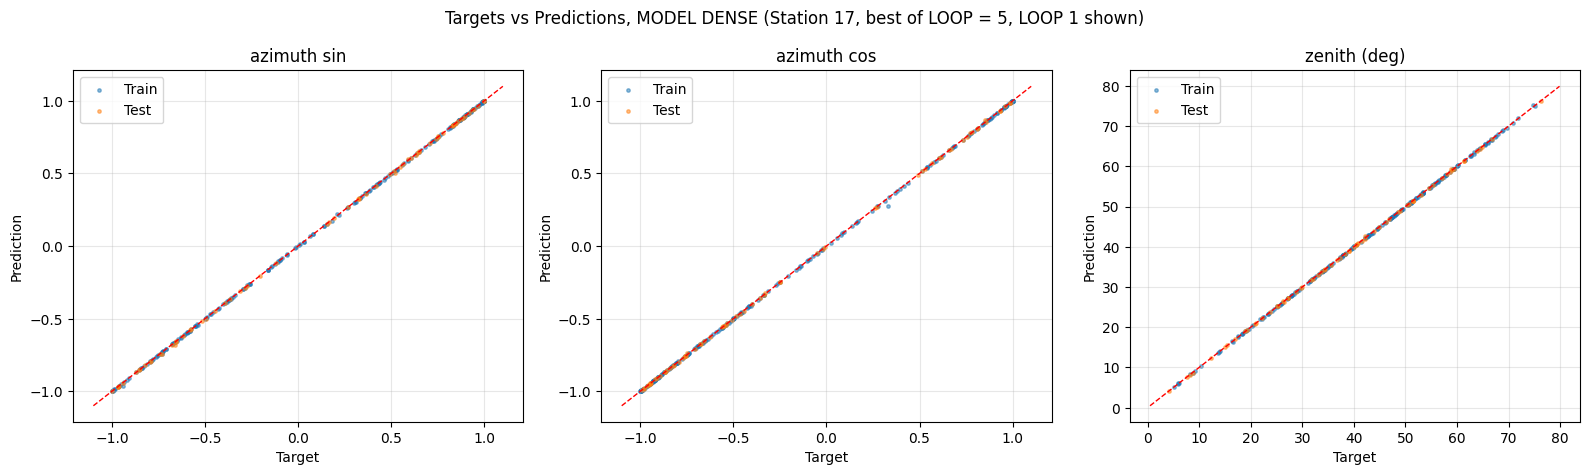

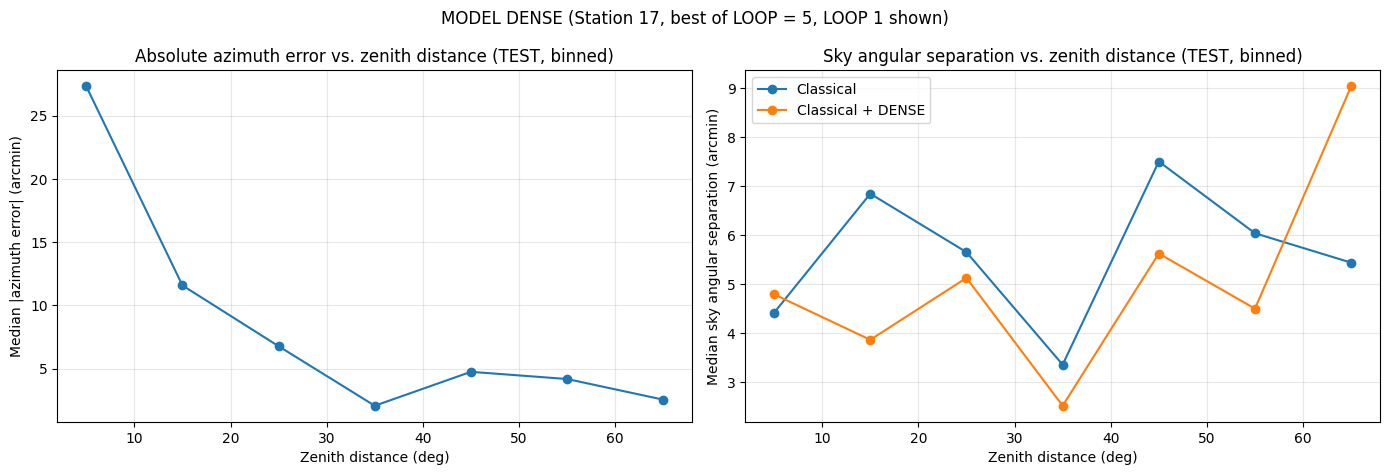

In [34]:
titulo = f"MODEL {MODEL_NAME} ({'Multi-station' if ES_GLOBAL else 'Station ' + str(ESTACION)}, best of LOOP = {LOOPS}, LOOP {best['loop']} shown)"

# Fig. a: curvas de entrenamiento
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(best['mse'], label='Train MSE'); ax[0].set_title('MSE per Epoch')
ax[1].plot(best['loss'], label='Train loss'); ax[1].plot(best['val_curve'], label='Validation loss'); ax[1].set_title('Loss per Epoch')
for a in ax: a.set_xlabel('Epoch'); a.legend(); a.grid(alpha=.3)
fig.suptitle(titulo); plt.tight_layout(); plt.show()

# Fig. b: targets vs predicciones (valores reales)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
for d, nombre, col in [(tr, 'Train', 'tab:blue'), (te, 'Test', 'tab:orange')]:
    zp, ap = to_za(v_red(d))
    for k, (t, p, lab) in enumerate([(np.sin(np.deg2rad(d['azimuth'])), np.sin(np.deg2rad(ap)), 'azimuth sin'),
                                     (np.cos(np.deg2rad(d['azimuth'])), np.cos(np.deg2rad(ap)), 'azimuth cos'),
                                     (d['zenith'], zp, 'zenith (deg)')]):
        ax[k].scatter(t, p, s=6, alpha=.5, color=col, label=nombre); ax[k].set_title(lab)
for a in ax:
    lim = [min(a.get_xlim()[0], a.get_ylim()[0]), max(a.get_xlim()[1], a.get_ylim()[1])]
    a.plot(lim, lim, 'r--', lw=1); a.set_xlabel('Target'); a.set_ylabel('Prediction'); a.legend(); a.grid(alpha=.3)
fig.suptitle('Targets vs Predictions, ' + titulo); plt.tight_layout(); plt.show()

# Figs. c y d: error vs cenit (test, binned), red vs clásico
z_p, a_p = to_za(v_red(te))
daz = np.abs((a_p - te['azimuth'].values + 180) % 360 - 180) * 60
edges = np.arange(0, 91, 10); cen = edges[:-1] + 5
def binned(e):
    return [np.median(e[(te['zenith'] >= lo) & (te['zenith'] < hi)]) if ((te['zenith'] >= lo) & (te['zenith'] < hi)).sum() >= 3 else np.nan
            for lo, hi in zip(edges[:-1], edges[1:])]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].plot(cen, binned(daz), 'o-'); ax[0].set_ylabel('Median |azimuth error| (arcmin)')
ax[0].set_title('Absolute azimuth error vs. zenith distance (TEST, binned)')
for e, lab in [(te['err_clasico'].values, 'Classical'), (err_test_red, f'Classical + {MODEL_NAME}')]:
    ax[1].plot(cen, binned(e), 'o-', label=lab)
ax[1].set_ylabel('Median sky angular separation (arcmin)'); ax[1].set_title('Sky angular separation vs. zenith distance (TEST, binned)')
for a in ax: a.set_xlabel('Zenith distance (deg)'); a.grid(alpha=.3)
ax[1].legend(); fig.suptitle(titulo); plt.tight_layout(); plt.show()

# 5. Guardar predicciones y paquete de calibración

In [35]:
t_pred_all = predecir(model, dfm)
pred = pd.DataFrame({'rid': dfm['rid'].values, 'station': dfm['station'].values, 'split': dfm['split'].values,
                     't_z_pred': t_pred_all[:, 0], 't_a_pred': t_pred_all[:, 1]})
pred_file = os.path.join(PATH_BASE, f"pred_{TAG}.csv")
pred.to_csv(pred_file, index=False)

paquete = dict(model_name=MODEL_NAME, estacion=ESTACION, state_dict=model.state_dict(),
               columns_data=COLUMNS_DATA, cont_features=CONT_FEATURES, columns_target=COLUMNS_TARGET,
               station_onehot_cols=STATION_ONEHOT_COLS, x_scaler=x_scaler, y_scaler=y_scaler,
               params_clasico=PARAMS_CLASICO, seed_split=SEED_SPLIT)
torch.save(paquete, os.path.join(PATH_BASE, f"sky_model_{TAG}.pth"))
display(pd.DataFrame({'archivo': [os.path.basename(pred_file), f"sky_model_{TAG}.pth"], 'filas': [len(pred), '-']}))

,archivo,filas
0,pred_DENSE_st17.csv,350
1,sky_model_DENSE_st17.pth,-


# 6. Ensemble single + multi (solo en corridas single-station)
Requiere haber corrido antes `ESTACION = 'global'` con el mismo `MODEL_NAME` (lee `pred_<MODEL>_global.csv`). El peso w se elige en validación (w ∈ [0, 1]); el test se usa una sola vez.

In [36]:
if ES_GLOBAL:
    display(pd.DataFrame({'info': ['Corrida multi-station: el ensemble se calcula en las corridas single.']}))
else:
    multi = pd.read_csv(os.path.join(PATH_BASE, f"pred_{MODEL_NAME}_global.csv")).set_index('rid')
    def preds(d):
        idx = d.index.values
        ts = predecir(model, d)
        tm = multi.loc[d['rid'].values, ['t_z_pred', 't_a_pred']].values
        return ts, tm, v_cl[idx], e_z[idx], e_a[idx], v_true[idx]

    def err_blend(w, ts, tm, vc, ez, ea, vt):
        return sep_arcmin(reconstruir(vc, ez, ea, w*tm + (1 - w)*ts), vt)

    pv = preds(va)
    barrido = pd.DataFrame([{'w': w, 'val_RMSE': np.sqrt(np.mean(err_blend(w, *pv)**2))} for w in np.round(np.arange(0, 1.0001, 0.05), 2)])
    w_star = barrido.loc[barrido['val_RMSE'].idxmin(), 'w']

    pt = preds(te)
    e_single, e_multi, e_blend = err_blend(0, *pt), err_blend(1, *pt), err_blend(w_star, *pt)
    display(pd.DataFrame({'Caldas (Xpred)': resumen(te['err_caldas'].values), 'Clásico propio': resumen(te['err_clasico'].values),
                          'Single': resumen(e_single), 'Multi': resumen(e_multi), f'Blend (w={w_star:.2f})': resumen(e_blend)}).T.round(2))

    # Bootstrap (pareado): single vs blend, y clásico vs blend
    rng = np.random.default_rng(42); n = len(e_single); B = 1000
    rmse = lambda e: np.sqrt(np.mean(e**2))
    d_sb, d_cb = [], []
    for _ in range(B):
        i = rng.integers(0, n, n)
        d_sb.append(rmse(e_single[i]) - rmse(e_blend[i]))
        d_cb.append(rmse(te['err_clasico'].values[i]) - rmse(e_blend[i]))
    d_sb, d_cb = np.array(d_sb), np.array(d_cb)

    # Controles: multi mezclado y ruido
    ts, tm = pt[0], pt[1]
    perm = rng.permutation(n)
    ruido = ts + rng.normal(0, tm.std(axis=0), size=ts.shape)
    e_shuf = sep_arcmin(reconstruir(pt[2], pt[3], pt[4], w_star*tm[perm] + (1 - w_star)*ts), pt[5])
    e_noise = sep_arcmin(reconstruir(pt[2], pt[3], pt[4], w_star*ruido + (1 - w_star)*ts), pt[5])

    display(pd.DataFrame([
        {'prueba': 'Bootstrap single − blend (RMSE)', 'gana_blend_%': 100*(d_sb > 0).mean(), 'media': d_sb.mean(),
         'IC95_inf': np.percentile(d_sb, 2.5), 'IC95_sup': np.percentile(d_sb, 97.5)},
        {'prueba': 'Bootstrap clásico − blend (RMSE)', 'gana_blend_%': 100*(d_cb > 0).mean(), 'media': d_cb.mean(),
         'IC95_inf': np.percentile(d_cb, 2.5), 'IC95_sup': np.percentile(d_cb, 97.5)},
    ]).round(3))
    display(pd.DataFrame({'RMSE (arcmin)': {'Single': rmse(e_single), 'Blend multi real': rmse(e_blend),
                                            'Blend multi mezclado': rmse(e_shuf), 'Blend ruido': rmse(e_noise)}}).T.round(2))

    # Fila de la Tabla 9 (se acumula en Drive)
    fila = dict(Station=int(ESTACION), N=len(dfm), N_test=n,
                RMSE_caldas=rmse(te['err_caldas'].values), RMSE_clasico=rmse(te['err_clasico'].values),
                RMSE_single=rmse(e_single), RMSE_multi=rmse(e_multi), RMSE_blend=rmse(e_blend),
                dRMSE_vs_single_pct=100*(rmse(e_blend)/rmse(e_single) - 1),
                dRMSE_vs_clasico_pct=100*(rmse(e_blend)/rmse(te['err_clasico'].values) - 1),
                MAE_clasico=te['err_clasico'].mean(), MAE_single=e_single.mean(), MAE_blend=e_blend.mean(),
                MED_clasico=te['err_clasico'].median(), MED_single=np.median(e_single), MED_blend=np.median(e_blend),
                w_star=w_star, IC95_single_blend=f"[{np.percentile(d_sb, 2.5):.2f}, {np.percentile(d_sb, 97.5):.2f}]")
    t9_file = os.path.join(PATH_BASE, f"tabla9_{MODEL_NAME}.csv")
    t9 = pd.read_csv(t9_file) if os.path.exists(t9_file) else pd.DataFrame()
    if len(t9):
        t9 = t9[t9['Station'] != int(ESTACION)]
    t9 = pd.concat([t9, pd.DataFrame([fila])], ignore_index=True).sort_values('Station')
    t9.to_csv(t9_file, index=False)
    print(f"Tabla 9 ({MODEL_NAME}, test, sky angular separation, arcmin) — {len(t9)} estaciones hasta ahora")
    display(t9.round(2))

,N,mediana,MAE,RMSE,P90
Caldas (Xpred),70.0,9.12,17.05,30.95,34.95
Clásico propio,70.0,6.08,7.03,10.44,10.21
Single,70.0,4.49,6.28,10.07,9.47
Multi,70.0,4.97,6.18,9.87,10.46
Blend (w=0.00),70.0,4.49,6.28,10.07,9.47


,prueba,gana_blend_%,media,IC95_inf,IC95_sup
0,Bootstrap single − blend (RMSE),0.0,0.000,0.000,0.000
1,Bootstrap clásico − blend (RMSE),69.2,0.517,-0.716,2.484


,Single,Blend multi real,Blend multi mezclado,Blend ruido
RMSE (arcmin),10.07,10.07,10.07,10.07


Tabla 9 (DENSE, test, sky angular separation, arcmin) — 1 estaciones hasta ahora


,Station,N,N_test,RMSE_caldas,RMSE_clasico,RMSE_single,RMSE_multi,RMSE_blend,dRMSE_vs_single_pct,dRMSE_vs_clasico_pct,MAE_clasico,MAE_single,MAE_blend,MED_clasico,MED_single,MED_blend,w_star,IC95_single_blend
0,17,350,70,30.95,10.44,10.07,9.87,10.07,0.0,-3.55,7.03,6.28,6.28,6.08,4.49,4.49,0.0,"[0.00, 0.00]"
